In [18]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import cartopy.crs as ccrs
from cartopy.util import add_cyclic_point

from matplotlib import font_manager as fm
# Path to your .ttf
font_path = "/home/links/mf671/times.ttf"

# Add the font to Matplotlib's font manager
fm.fontManager.addfont(font_path)

# Get the name of the font inside the .ttf
font_name = fm.FontProperties(fname=font_path).get_name()

# Set as default
plt.rcParams['font.family'] = font_name
plt.rcParams['font.size'] = 12
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 12

In [12]:
def zonalize(ds):
    """Replace every field that has a 'lon' dimension with its zonal mean,
    repeated along lon, so the result is zonally symmetric.
    Fields without 'lon' (scalars, lat-only fields, coordinates) are left untouched."""
    out = ds.copy()
    for name, da in ds.data_vars.items():
        if 'lon' in da.dims:
            zm = da.mean('lon', skipna=True, keep_attrs=True)
            out[name] = (zm.expand_dims(lon=ds.lon)
                           .transpose(*da.dims)
                           .assign_attrs(da.attrs))
    return out

In [5]:
# =============================================================================
# 1. DATA
# =============================================================================
path_SYM = "/home/links/mf671/DATA/isca_data/exeter_project_mf_baseline_KS/tot/FC_1.5x1.5_2-51_wbeta.nc"    # <-- set me
path_ASYM = "/home/links/mf671/DATA/isca_data/exeter_project_mf_baseline_st_KS/tot/FC_1.5x1.5_2-51_wbeta.nc"  # <-- set me

ds_SYM = xr.open_dataset(path_SYM)
ds_ASYM = xr.open_dataset(path_ASYM)

In [13]:
ds_SYM = zonalize(ds_SYM)

In [14]:
ds_ASYM['qslwa'] = xr.where(ds_ASYM['qslwa']<0,0,ds_ASYM['qslwa'])

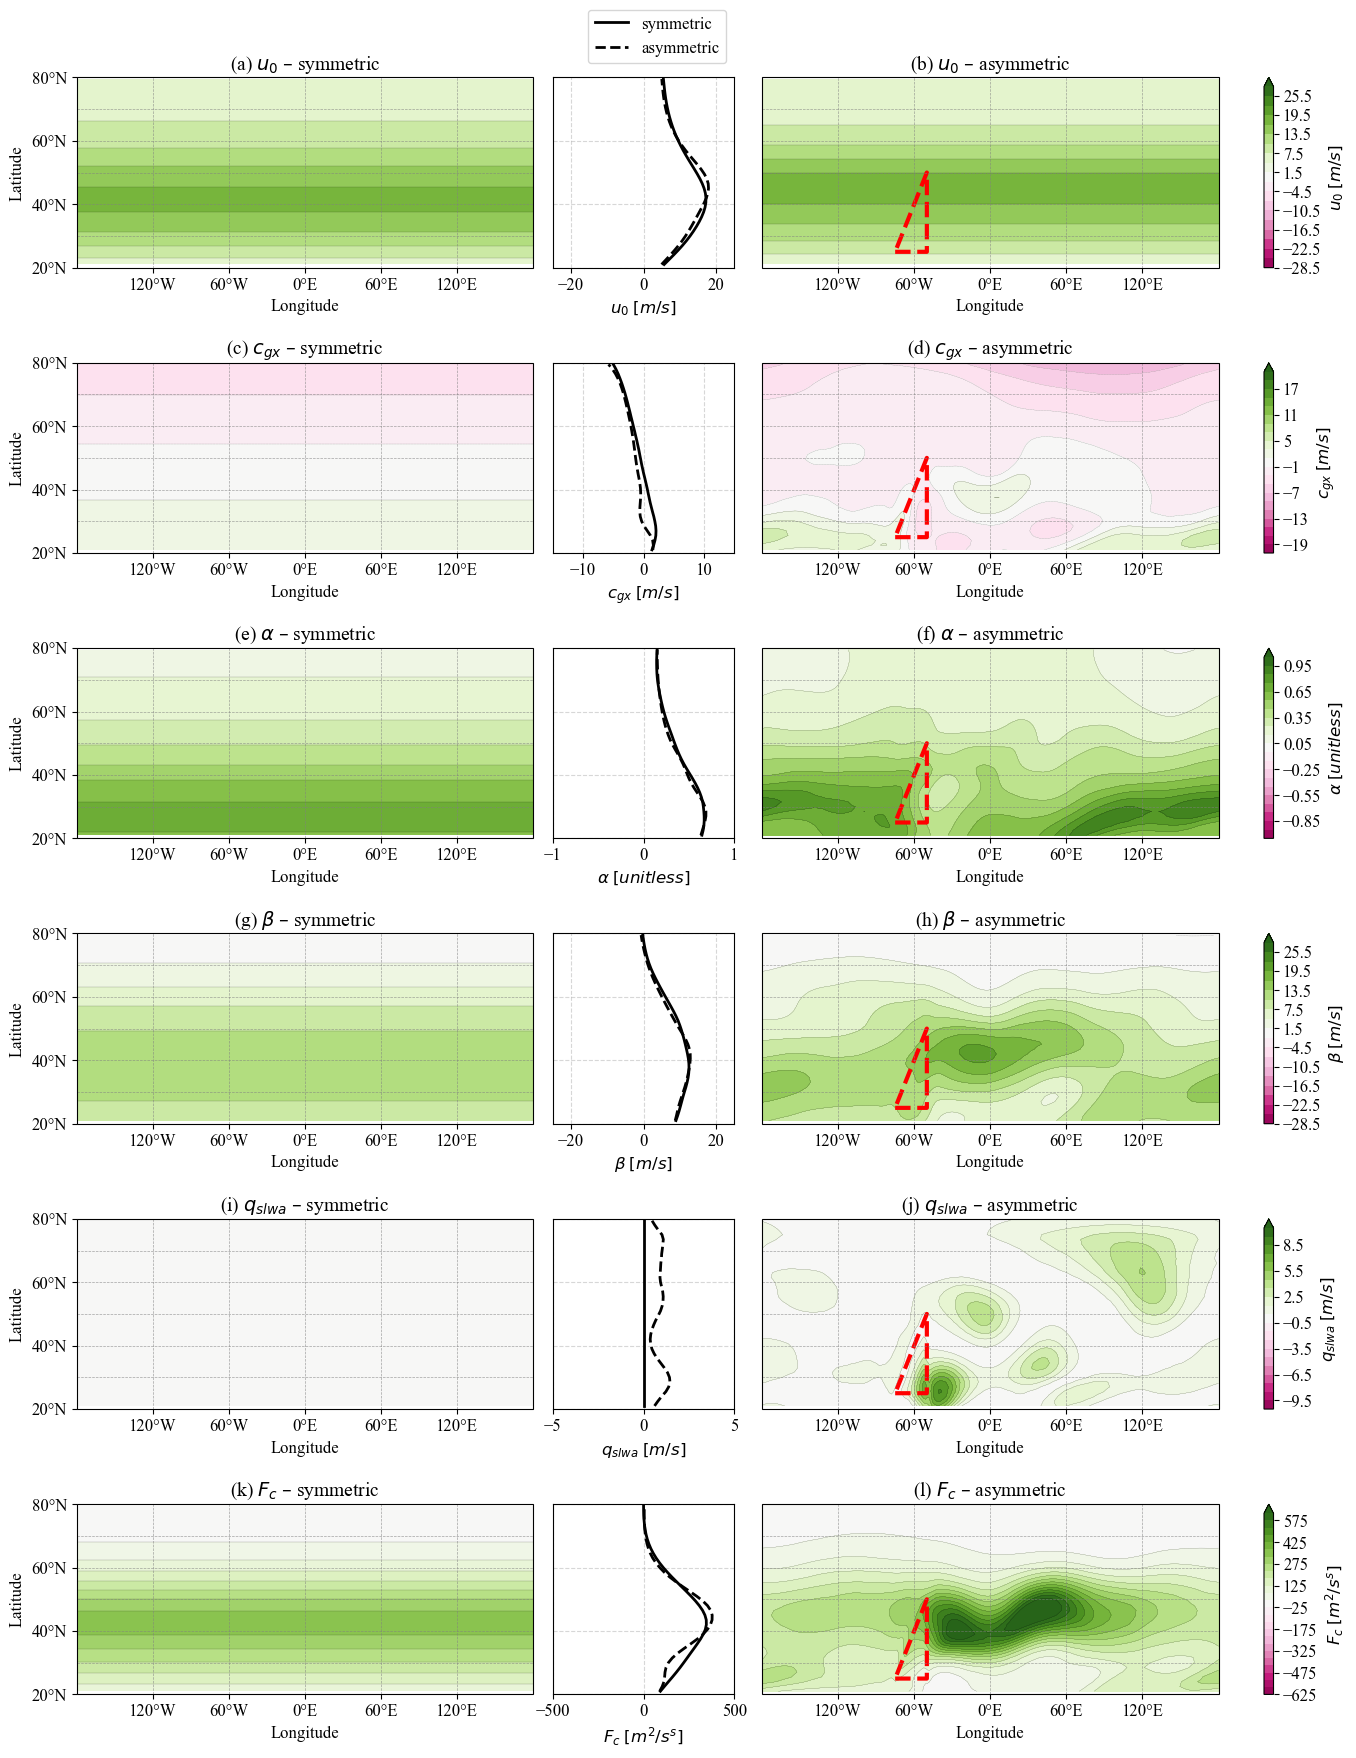

In [21]:
# --------------------------------------------------
# Settings to check
# --------------------------------------------------
LAT_MIN, LAT_MAX = 20, 80

def crop_lat(ds):
    """Keep only LAT_MIN-LAT_MAX, whatever the latitude ordering."""
    ascending = bool(ds.lat[0] < ds.lat[-1])
    sl = slice(LAT_MIN, LAT_MAX) if ascending else slice(LAT_MAX, LAT_MIN)
    return ds.sel(lat=sl)

def to_180(ds):
    """lon -> [-180, 180), sorted."""
    return ds.assign_coords(lon=((ds.lon + 180) % 360) - 180).sortby('lon')

ds_SYM  = crop_lat(to_180(ds_SYM))
ds_ASYM = crop_lat(to_180(ds_ASYM))

# Rows, in order: (variable, label used in titles / axis labels)
ROWS = [
    ('u_0',   r"$u_0$"     ,  r"$u_0$ $[m/s]$"),
    ('zgv',   r"$c_{gx}$"  ,  r"$c_{gx}$ $[m/s]$"),
    ('alpha', r"$\alpha$"  , r"$\alpha$ $[unitless]$"),
    ('beta',  r"$\beta$"   , r"$\beta$ $[m/s]$"),
    ('qslwa', r"$q_{slwa}$", r"$q_{slwa}$ $[m/s]$"),
    ('FC',    r"$F_c$"     , r"$F_c$ $[m^2/s^s]$"),
]

# ==================================================
# ADJUSTABLE: contourf levels (maps) and x limits (cross sections)
# ==================================================
LEVELS = {
    'u_0':   np.arange(-28.5, 29, 3),
    'zgv':   np.arange(-21, 22, 2),
    'alpha': np.arange(-1.05, 1.1, 0.1),
    'beta':  np.arange(-28.5, 29, 3),
    'qslwa': np.arange(-10.5, 11, 1),
    'FC':    np.arange(-625, 640, 50),
}
XLIMS = {
    'u_0':   (-25, 25),
    'zgv':   (-15, 15),
    'alpha': (-1, 1),
    'beta':  (-25, 25),
    'qslwa': (-5, 5),
    'FC':    (-500, 500),
}
CMAP   = 'PiYG'
EXTEND = 'max'          # 'neither', 'max', 'min', 'both'

# ==================================================
# Figure layout (same as the previous figure, 6 rows)
# ==================================================
nrows = len(ROWS)
fig = plt.figure(figsize=(20, 21))
gs = gridspec.GridSpec(
    nrows=nrows, ncols=5,
    width_ratios=[6.0, 0.25, 1.2, 0.01, 6.0],
    hspace=0.5, wspace=-0.3
)

titles  = ['symmetric', 'asymmetric']
# left column: (a),(c),(e),...; right column: (b),(d),(f),...
letters = [f'({chr(97 + k)})' for k in range(2 * nrows)]
colors  = ['k', 'k']                  # zonal means: SYM solid, ASYM dashed
ls_xsec = ['-', '--']

# red triangle
coords = [(-75.0, 25.0), (-50.0, 25.0), (-50.0, 50.0)]
lons, lats = zip(*coords)
lons = np.array(lons)
lats = np.array(lats)
lons_closed = np.append(lons, lons[0])
lats_closed = np.append(lats, lats[0])

proj = ccrs.PlateCarree()

# --------------------------------------------------
# Helpers
# --------------------------------------------------
def style_map(ax_map, i):
    ax_map.set_aspect(2.5)
    ax_map.set_ylim(LAT_MIN, LAT_MAX)
    ax_map.set_xticks([-120, -60, 0, 60, 120], crs=proj)
    ax_map.set_xticklabels(['120°W', '60°W', '0°E', '60°E', '120°E'])
    ax_map.set_xlabel('Longitude')

    if i == 0:
        ax_map.set_yticks([20, 40, 60, 80])
        ax_map.set_yticklabels(['20°N', '40°N', '60°N', '80°N'])
        ax_map.set_ylabel('Latitude')
    else:
        plt.setp(ax_map.get_yticklabels(), visible=False)
        ax_map.plot(lons_closed, lats_closed, '--', lw=3, color='red', transform=proj)

    ax_map.gridlines(draw_labels=False, linewidth=0.5, color='gray', alpha=0.7, linestyle='--')

def style_xsec(ax):
    ax.set_ylim(LAT_MIN, LAT_MAX)
    ax.grid(True, ls='--', alpha=0.5)
    ax.tick_params(axis='y', length=0)
    plt.setp(ax.get_yticklabels(), visible=False)

def plot_map(ax, da, levels):
    data, lon = add_cyclic_point(da.values, coord=da.lon.values)
    return ax.contourf(lon, da.lat.values, data, levels=levels,
                       cmap=CMAP, extend=EXTEND, transform=proj)

def plot_highlight_map(ax, da, levels):
    data, lon = add_cyclic_point(da.values, coord=da.lon.values)
    return ax.contour(lon, da.lat.values, data, levels=levels,
                       colors = 'black', linewidths=0.1, transform=proj)

# --------------------------------------------------
# Loop over rows (variables); columns: SYM map | zonal means | ASYM map
# --------------------------------------------------
dsets = [ds_SYM, ds_ASYM]
lat = ds_SYM.lat.values

for r, (var, label_t, label) in enumerate(ROWS):

    XSEC_COL = 2
    levels = LEVELS[var]

    # cross section axis (shared y with both maps of this row)
    ax_xsec = fig.add_subplot(gs[r, XSEC_COL])

    for i in range(2):
        MAP_COL = 0 if i == 0 else 4
        da = dsets[i][var]

        ax_map = fig.add_subplot(gs[r, MAP_COL], projection=proj, sharey=ax_xsec)
        ax_map.set_title(f"{letters[r * 2 + i]} {label_t} – {titles[i]}")

        cf = plot_map(ax_map, da, levels)
        chf = plot_highlight_map(ax_map, da, levels)
        style_map(ax_map, i)

        if i > 0:
            fig.colorbar(cf, ax=ax_map, label=label)

        # zonal mean in the middle panel
        zm = da.mean('lon', skipna=True).values
        ax_xsec.plot(zm, lat, color=colors[i], ls=ls_xsec[i], lw=2, label=titles[i])

    ax_xsec.set_xlabel(label)
    ax_xsec.set_xlim(XLIMS[var])
    if r == 0:
        ax_xsec.legend(loc='upper right', bbox_to_anchor=(1.0, 1.4))
    style_xsec(ax_xsec)

# --------------------------------------------------
plt.savefig('PLOTS/Figure_2.png', dpi=300, bbox_inches='tight')
plt.show()